# Reduced Dynamics of a Qubit Coupled to a Coherent Spectator

Jai Veilleux · IBM Fez experiment

The central qubit exchanges excitation with a spectator that either stays in place or is reset after each block. This notebook uses the 567 measured count records from three jobs. It follows the measured population, trace distance between two input trajectories, and coherence from a plus-state preparation.

The [paper](paper/paper.pdf) develops the fixed channel and the memory-kernel approximation. The [protocol](README.md) describes the circuits and the offline Python dependencies.

In [ ]:
%matplotlib inline

from analyze import analyze
from design import ROOT, read_json
from IPython.display import Markdown, display
from matplotlib import pyplot as plt
from report import plot_experiment

data = ROOT / "data"
plan = read_json(data / "plan.json")
assert plan["source"] == "hardware"
tables = analyze(data)

print(f"Backend: {plan['backend']}")
print(f"Central and spectator qubits: {plan['physical_pair']}")
print(f"{plan['repeats']} jobs x {len(plan['circuits'])} circuits x {plan['shots']} shots")


def show_table(headers, rows):
    """Display column labels and an iterable of matching rows as Markdown."""
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

Backend: ibm_fez
Central and spectator qubits: [131, 132]
3 jobs × 189 circuits × 512 shots


## Population, distinguishability, and coherence

For each Pauli basis, the outcome-1 fraction $k_P/N$ gives $\hat r_P=1-2k_P/N$. The raw $Z$ counts give the population. Trace distances use radial projection of any reconstructed Bloch vector outside the unit ball. The raw $X$ expectation shows the sign of the coherence for the plus input.

The exact no-reset amplitude is $\cos(n\theta)$. The ideal reset amplitude is $(\cos\theta)^n$. For the excited input, the population is the squared amplitude. The plus input's $X$ expectation is the amplitude itself. The markers show averages across jobs, with bars spanning the observed job ranges.

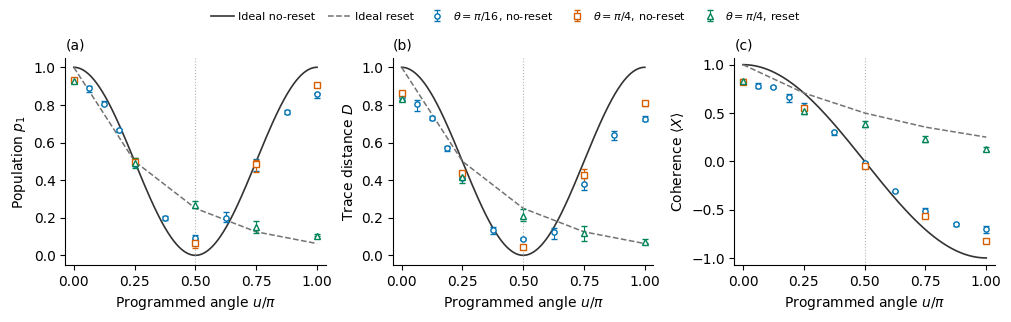

In [2]:
figure = plot_experiment(tables)
display(figure)
plt.close(figure)

## Measure the two-input distance change

Trace distance is half the Euclidean separation of the ground- and excited-input Bloch vectors. The contrast uses the programmed transfer and return angles $\pi/2$ and $\pi$ in each sweep. The intervals come from a 2,000-draw shot bootstrap within each job.

The contrast tests the same post-preparation exchange sequence for the two inputs. Preparation-dependent noise and readout can affect the measured witness. The intervals describe shot variation for each job.

In [3]:
sweep_labels = {
    "small": "π/16 no-reset",
    "large": "π/4 no-reset",
    "reset": "π/4 reset",
}
show_table(
    ("Job", "Sweep", "Distance at transfer", "Distance at return", "Change [95% shot interval]"),
    (
        (r["repeat"], sweep_labels[r["sweep"]], f"{r['distance_at_transfer']:.3f}",
         f"{r['distance_at_return']:.3f}", f"{r['increase']:.3f} [{r['lo95']:.3f}, {r['hi95']:.3f}]")
        for r in tables["witness"]
    ),
)

| Job | Sweep | Distance at transfer | Distance at return | Change [95% shot interval] |
| --- | --- | --- | --- | --- |
| 1 | π/16 no-reset | 0.089 | 0.715 | 0.627 [0.554, 0.686] |
| 1 | π/4 no-reset | 0.041 | 0.821 | 0.781 [0.703, 0.820] |
| 1 | π/4 reset | 0.246 | 0.068 | -0.178 [-0.229, -0.110] |
| 2 | π/16 no-reset | 0.094 | 0.712 | 0.618 [0.544, 0.681] |
| 2 | π/4 no-reset | 0.046 | 0.818 | 0.771 [0.699, 0.818] |
| 2 | π/4 reset | 0.201 | 0.086 | -0.115 [-0.166, -0.050] |
| 3 | π/16 no-reset | 0.084 | 0.740 | 0.656 [0.580, 0.716] |
| 3 | π/4 no-reset | 0.044 | 0.796 | 0.753 [0.674, 0.796] |
| 3 | π/4 reset | 0.180 | 0.064 | -0.117 [-0.171, -0.050] |

## Compare predictions fixed before scoring

The ideal exchange and reset curves use the circuit angle. The no-reset calibration model adds independent local relaxation and dephasing based on the reported $T_1/T_2$ and the scheduled duration of each block. It has no model for readout or coherent gate errors. The exact and calibration models are scored over the full measured range. The paper also evaluates the near-origin TCL2/TCL4 approximations over the shared early window, $u\leq\pi/4$.

In [4]:
names = {
    "exact-exchange": "Ideal exchange",
    "calibrated-block-noise": "Scheduled local noise",
    "fresh-spectator": "Ideal reset",
}
show_table(
    ("Job", "Sweep", "Model", "Mean trace distance [95% shot interval]"),
    (
        (r["repeat"], sweep_labels[r["sweep"]], names[r["model"]],
         f"{r['value']:.4f} [{r['lo95']:.4f}, {r['hi95']:.4f}]")
        for r in tables["model_scores"]
        if r["window"] == "all observed" and r["metric"] == "mean_trace_distance"
    ),
)

| Job | Sweep | Model | Mean trace distance [95% shot interval] |
| --- | --- | --- | --- |
| 1 | π/16 no-reset | Ideal exchange | 0.0986 [0.0984, 0.1098] |
| 1 | π/16 no-reset | Scheduled local noise | 0.0932 [0.0933, 0.1048] |
| 1 | π/4 no-reset | Ideal exchange | 0.0766 [0.0751, 0.0910] |
| 1 | π/4 no-reset | Scheduled local noise | 0.0748 [0.0733, 0.0892] |
| 1 | π/4 reset | Ideal reset | 0.0806 [0.0788, 0.0954] |
| 2 | π/16 no-reset | Ideal exchange | 0.0943 [0.0944, 0.1055] |
| 2 | π/16 no-reset | Scheduled local noise | 0.0893 [0.0896, 0.1006] |
| 2 | π/4 no-reset | Ideal exchange | 0.0751 [0.0743, 0.0900] |
| 2 | π/4 no-reset | Scheduled local noise | 0.0738 [0.0728, 0.0887] |
| 2 | π/4 reset | Ideal reset | 0.0815 [0.0795, 0.0969] |
| 3 | π/16 no-reset | Ideal exchange | 0.0951 [0.0949, 0.1062] |
| 3 | π/16 no-reset | Scheduled local noise | 0.0885 [0.0886, 0.1000] |
| 3 | π/4 no-reset | Ideal exchange | 0.0817 [0.0801, 0.0955] |
| 3 | π/4 no-reset | Scheduled local noise | 0.0797 [0.0782, 0.0936] |
| 3 | π/4 reset | Ideal reset | 0.0809 [0.0791, 0.0963] |

## Results

Both no-reset sweeps recover distinguishability from transfer to return in all three jobs. Over the same interval, the reset control loses distinguishability. The raw $X$ expectation at the last block is negative in each no-reset sweep and positive in the reset control, as predicted by the two ideal channels.

At the return angle, the sixteen-block circuit has a smaller excited-state population than the four-block circuit in all three jobs. The circuits target the same ideal unitary. Their elapsed time and gate count differ together, so the comparison does not isolate the hardware mechanism.